# Naive Bayes génératif vs régression logistique discriminative
**Navigation** : [<< 2.3 Régression linéaire/logistique](2.3-Regression-lineaire-logistique.ipynb) | [2.3c Régression en grande dimension >>](2.3c-Regression-Grande-Dimension.ipynb) | [Index 02-ML-Cours](README.md) | [Version Python](2.3b-Naive-Bayes-Generatif.ipynb)


Un classifieur peut modéliser **deux façons opposées** de conditionner la probabilité :

- **Génératif** (Naive Bayes) : on modélise **comment les données sont produites** — `P(x|y)` et `P(y)` — puis on en déduit `P(y|x)` par la règle de Bayes. On apprend le **processus**.
- **Discriminatif** (régression logistique) : on modélise **directement** `P(y|x)`, sans se soucier de comment `x` est généré. On apprend la **frontière**.

Le point pédagogique : ce choix impose des hypothèses différentes et peut modifier le compromis biais–variance. Dans les expériences ci-dessous, l'avantage varie avec le scénario et la taille du train. GaussianNB peut produire une frontière quadratique lorsque les variances diffèrent par classe, tandis que la logistique est linéaire en log-odds : aucune hiérarchie générale de flexibilité ne découle des seules étiquettes génératif et discriminatif.

> **Fil conducteur.** On implémente un *Naive Bayes* gaussien de zéro, on le vérifie contre `sklearn`, puis on le met en face de la **régression logistique de [2.3](2.3-Regression-lineaire-logistique.ipynb)** en faisant varier la taille du jeu d'entraînement. On compare **deux scénarios corrélés**, l'un homogène à ρ=0,6 et l'autre en blocs à ρ=0,85 ; l'indépendance conditionnelle est violée dans les deux.

Les avantages comparés sont des observations sur les scénarios construits ici, et non des garanties pour toutes données rares, corrélées ou abondantes.


[Jumeau Python](2.3b-Naive-Bayes-Generatif.ipynb)

**Environnement C#** : installer NumPy et scikit-learn dans un CPython compatible avec Python.NET, définir `PYTHONNET_PYDLL` et, selon votre installation, `PYTHONHOME`/`PYTHONPATH`. Le classifieur gaussien de base et les métriques sont calculés en C# ; les courbes utilisent les véritables estimateurs sklearn.

In [1]:
#r "nuget: PythonNet, 3.0.5"
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using System.Text.Json;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (String.IsNullOrWhiteSpace(library))
    {
        throw new InvalidOperationException("Configurer PYTHONNET_PYDLL, PYTHONHOME et PYTHONPATH pour NumPy et scikit-learn.");
    }
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
double[][] ReadMatrix(JsonElement element)
{
    return element.EnumerateArray().Select(row => row.EnumerateArray().Select(value => value.GetDouble()).ToArray()).ToArray();
}
int[] ReadInts(JsonElement element)
{
    return element.EnumerateArray().Select(value => value.GetInt32()).ToArray();
}
PyModule py;
using (Py.GIL())
{
    py = Py.CreateScope();
    // NumPy conserve exactement la séquence de tirage et sklearn fournit les vraies références.
    py.Exec(@"import json, numpy as np, sklearn
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(7)
Xs = rng.normal(0,1,(200,6))
ys = rng.integers(0,2,200)
Xs[ys == 1] += 1.2
ref = GaussianNB().fit(Xs,ys)
validation = json.dumps(dict(X=Xs.tolist(), y=ys.tolist(), pred=ref.predict(Xs).tolist(), mean=ref.theta_.tolist(), numpy=np.__version__, sklearn=sklearn.__version__))");
}
JsonElement validation;
using (Py.GIL())
{
    validation = JsonDocument.Parse(py.Get("validation").As<string>()).RootElement;
}
var sampleX = ReadMatrix(validation.GetProperty("X"));
var sampleY = ReadInts(validation.GetProperty("y"));
var sampleSk = ReadInts(validation.GetProperty("pred"));
Console.WriteLine($"NumPy {validation.GetProperty("numpy").GetString()} ; scikit-learn {validation.GetProperty("sklearn").GetString()} ; {sampleY.Length} observations, {sampleX[0].Length} variables");

Installed Packages MathNet.Numerics, 5.0.0 PythonNet, 3.0.5

NumPy 2.3.5 ; scikit-learn 1.8.0 ; 200 observations, 6 variables


### 1. Le classifieur génératif — Naive Bayes gaussien from scratch

Le Naive Bayes gaussien modélise chaque classe par des **gaussiennes indépendantes** :
`P(x|y=c) = ∏_j N(x_j ; μ_{c,j}, σ²_{c,j})`. L'**indépendance** (le « naive ») fait qu'on estime chaque variable séparément par sa moyenne et sa variance, puis on combine par le produit.

À la prédiction, on applique Bayes :
`P(y=c|x) ∝ P(y=c) · ∏_j N(x_j ; μ_{c,j}, σ²_{c,j})`.
On choisit la classe de **log-vraisemblance postérieure** maximale — c'est un produit, on travaille donc en log pour éviter les underflows.

In [2]:
public sealed class GaussianNb
{
    public int[] Classes { get; private set; }
    public double[][] Means { get; private set; }
    public double[][] Variances { get; private set; }
    public double[] Priors { get; private set; }

    public GaussianNb Fit(double[][] x, int[] labels)
    {
        Classes = labels.Distinct().OrderBy(value => value).ToArray();
        Means = new double[Classes.Length][];
        Variances = new double[Classes.Length][];
        Priors = new double[Classes.Length];
        for (int c = 0; c < Classes.Length; c++)
        {
            var rows = Enumerable.Range(0, labels.Length)
                .Where(i => labels[i] == Classes[c]).Select(i => x[i]).ToArray();
            Means[c] = new double[x[0].Length];
            Variances[c] = new double[x[0].Length];
            Priors[c] = rows.Length / (double)labels.Length;
            for (int j = 0; j < x[0].Length; j++)
            {
                // Variance de population, comme la source ; l'epsilon évite log(0).
                double mean = rows.Average(row => row[j]);
                Means[c][j] = mean;
                Variances[c][j] = rows.Average(row => Math.Pow(row[j] - mean, 2)) + 1e-9;
            }
        }
        return this;
    }

    public double[][] LogLikelihood(double[][] x)
    {
        var scores = new double[Classes.Length][];
        for (int c = 0; c < Classes.Length; c++)
        {
            scores[c] = new double[x.Length];
            for (int i = 0; i < x.Length; i++)
            {
                double score = Math.Log(Priors[c]);
                for (int j = 0; j < x[i].Length; j++)
                {
                    double difference = x[i][j] - Means[c][j];
                    score -= 0.5 * (Math.Log(2 * Math.PI * Variances[c][j]) +
                                    difference * difference / Variances[c][j]);
                }
                scores[c][i] = score;
            }
        }
        return scores;
    }

    public int[] Predict(double[][] x)
    {
        var scores = LogLikelihood(x);
        return Enumerable.Range(0, x.Length).Select(i =>
            Classes[Enumerable.Range(0, Classes.Length).OrderByDescending(c => scores[c][i]).First()]).ToArray();
    }
}
Console.WriteLine("Naive Bayes gaussien natif prêt.");

Naive Bayes gaussien natif prêt.


In [3]:
// Comparer la classe native et GaussianNB sur le même tirage NumPy.
var mine = new GaussianNb().Fit(sampleX, sampleY);
var predicted = mine.Predict(sampleX);
double myAccuracy = predicted.Select((value, i) => value == sampleY[i] ? 1.0 : 0.0).Average();
double refAccuracy = sampleSk.Select((value, i) => value == sampleY[i] ? 1.0 : 0.0).Average();
Console.WriteLine($"accuracy from scratch : {myAccuracy:F4}");
Console.WriteLine($"accuracy sklearn : {refAccuracy:F4}");
Console.WriteLine($"prédictions identiques : {predicted.SequenceEqual(sampleSk)}");
Console.WriteLine($"moyenne classe 1, trois premières : {String.Join(", ", mine.Means[1].Take(3).Select(v => v.ToString("F3")))}");
var meansReference = ReadMatrix(validation.GetProperty("mean"));
Console.WriteLine($"écart maximal de moyennes à sklearn : {mine.Means[1].Zip(meansReference[1], (a,b) => Math.Abs(a-b)).Max():E3}");

accuracy from scratch : 0.9250


accuracy sklearn : 0.9250


prédictions identiques : True


moyenne classe 1, trois premières : 1.262, 0.913, 1.160


écart maximal de moyennes à sklearn : 0.000E+000


### Lecture — la vérification porte sur ce tirage

Le from-scratch et `sklearn` donnent la **même précision** (0.925) et **exactement les mêmes prédictions** (les classes coïncident bit à bit). Les moyennes de classe apprises sont identiques : sur la classe 1, chaque dimension est décalée de **l'ordre de +1** par rapport à la classe 0 — précisément le `+1.2` imposé à la génération, les moyennes échantillonnées s'en écartant légèrement (`[1.26, 0.91, 1.16]` sur les trois premières valeurs). Le code **reproduit** la lib de référence, sur les mêmes données : la série gagne la même exigence de preuve que le reste du catalogue.

Cette concordance de prédictions sur un échantillon est un contrôle utile, pas une preuve générale de l’implémentation ou de l’égalité exacte des probabilités ; les deux stabilisations de variance peuvent aussi différer.


### Exercice 1 — Multinomial Naive Bayes (variables discrètes)

Le gaussien convient aux variables continues. Pour des **comptages** (mots, fréquences), on utilise le Naive Bayes **multinomial** : `P(x|y=c) = ∏_j θ_{c,j}^{x_j}`. Implémente-le de zéro (estime `θ_{c,j}` par lissage Laplace) puis vérifie-le contre `sklearn.naive_bayes.MultinomialNB`.

In [4]:
double[][] ExerciseMultinomial(double[][] x, int[] labels)
{
    // TODO : retourner les probabilités par classe triée, avec lissage de Laplace alpha=1.
    return null;
}
var countSets = new[]
{
    (new[] { new[] { 2.0,0.0,1.0 }, new[] { 0.0,3.0,0.0 }, new[] { 1.0,0.0,0.0 }, new[] { 0.0,1.0,2.0 } }, new[] { 0,1,0,1 }),
    (new[] { new[] { 0.0,0.0 }, new[] { 4.0,0.0 }, new[] { 1.0,3.0 }, new[] { 0.0,2.0 }, new[] { 2.0,0.0 }, new[] { 0.0,1.0 } }, new[] { 0,1,2,2,0,1 })
};
var answers = countSets.Select(fixture => ExerciseMultinomial(fixture.Item1,fixture.Item2)).ToArray();
if (answers.All(answer => answer == null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if (answers.Any(answer => answer == null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok = true;
    for (int i=0; i<countSets.Length; i++)
    {
        var (x,y) = countSets[i];
        var classes = y.Distinct().OrderBy(label => label).ToArray();
        ok = ok && answers[i].Length == classes.Length;
        for (int c=0; c<classes.Length && ok; c++)
        {
            int label = classes[c];
            var counts = Enumerable.Range(0,x[0].Length).Select(j => Enumerable.Range(0,y.Length).Where(k => y[k]==label).Sum(k => x[k][j]) + 1).ToArray();
            double total = counts.Sum();
            ok = answers[i][c].Length == counts.Length && answers[i][c].Select((value,j) => double.IsFinite(value) && Math.Abs(value-counts[j]/total)<1e-12).All(value => value);
        }
    }
    Console.WriteLine(ok ? "Exercice 1 : probabilités correctes ; vérifier aussi les prédictions demandées" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


### Ce que votre complétion doit produire — le guide de l'exercice 1

Le Multinomial NB remplace les densités gaussiennes par des **comptages** : une distribution de probabilité sur les occurrences (mots, tokens, catégories) plutôt qu'un ajustement en cloche. Trois pièges classiques guident la complétion. D'abord, calculez les log-probabilités et sommez — le produit de milliers de probabilités inférieures à 1 sous-flotte en `float64` bien avant la fin du vocabulaire ; l'espace log est la pratique universelle, pas un raffinement. Ensuite, le **lissage de Laplace** (`+1` aux comptes, normalisation au vocabulaire `+V`) : sans lui, un mot absent du train attribue une probabilité nulle à toute la classe, où qu'il apparaisse — une seule observation invisible tuerait le verdict. Enfin, la contre-épreuve attendue : vos probabilités a posteriori doivent reproduire les prédictions de `sklearn.naive_bayes.MultinomialNB` exactement, comme la cellule 1.2 l'a fait pour le cas gaussien — la vérification porte sur ce tirage, toujours.

### 2. Le compromis génératif-discriminatif (mesuré, pas raconté)

On met Naive Bayes face à la **régression logistique** (le discriminatif de [2.3](2.3-Regression-lineaire-logistique.ipynb)) sur des données **gaussiennes corrélées**, en faisant varier la taille du jeu d'entraînement `n`. On mesure la **précision** de chaque modèle sur un même jeu de test fixe, moyennée sur plusieurs graines.

Deux scénarios, deux régimes :

- **Scénario A — corrélation homogène, modérée.** La corrélation 0,6 viole aussi l'indépendance conditionnelle ; elle est homogène plutôt qu'en blocs. On attend l'avantage génératif en petit `n`, puis convergence.
- **Scénario B — corrélation en bloc, forte.** L'hypothèse d'indépendance est **fausse**. Naive Bayes est plafonné par son **biais** ; la logistique, plus flexible, continue de progresser avec les données.

In [5]:
using (Py.GIL())
{
    // Ces deux générateurs reprennent l'ordre des appels RNG de la source Python.
    py.Exec(@"def make_corr(n,d,shift,rho,rng):
 z=rng.normal(0,1,n)
 X=np.sqrt(rho)*z[:,None]+np.sqrt(1-rho)*rng.normal(0,1,(n,d))
 y=rng.integers(0,2,n)
 X[y==1]+=shift
 return X,y
def make_block(n,d,shift,rho,rng):
 d1=d//2
 z=rng.normal(0,1,n)
 X=np.empty((n,d))
 X[:,:d1]=np.sqrt(rho)*z[:,None]+np.sqrt(1-rho)*rng.normal(0,1,(n,d1))
 X[:,d1:]=rng.normal(0,1,(n,d-d1))
 y=rng.integers(0,2,n)
 X[y==1]+=shift
 return X,y");
}
public record NbCurve(int[] Sizes, double[] Naive, double[] Logistic);
NbCurve EvaluateCurve(bool block, int dimension, double shift, double rho, int seed)
{
    var sizes = new[] { 15, 30, 60, 120, 240, 480, 960, 1920 };
    var nb = new double[sizes.Length];
    var lr = new double[sizes.Length];
    int[] testLabels;
    using (Py.GIL())
    {
        py.Set("dimension", new PyInt(dimension));
        py.Set("shift", new PyFloat(shift));
        py.Set("rho", new PyFloat(rho));
        py.Set("seed", new PyInt(seed));
        py.Set("block", new PyInt(block ? 1 : 0));
        py.Exec(@"gen=np.random.default_rng(int(seed))
make=make_block if int(block) else make_corr
Xt,yt=make(2000,int(dimension),float(shift),float(rho),gen)
labels_json=json.dumps(yt.tolist())");
        testLabels = ReadInts(JsonDocument.Parse(py.Get("labels_json").As<string>()).RootElement);
    }
    for (int run = 0; run < 40; run++)
    {
        using (Py.GIL())
        {
            py.Exec("X,y=make(3840,int(dimension),float(shift),float(rho),gen)");
        }
        for (int k = 0; k < sizes.Length; k++)
        {
            int[] predictionsNb;
            int[] predictionsLr;
            using (Py.GIL())
            {
                py.Set("sample_size", new PyInt(sizes[k]));
                // Chaque modèle est ajusté indépendamment sur le préfixe demandé.
                py.Exec(@"subset=int(sample_size)
model_nb=GaussianNB().fit(X[:subset],y[:subset])
model_lr=LogisticRegression(max_iter=8000,C=1e6).fit(X[:subset],y[:subset])
pred_json=json.dumps(dict(nb=model_nb.predict(Xt).tolist(),lr=model_lr.predict(Xt).tolist()))");
                var predictions = JsonDocument.Parse(py.Get("pred_json").As<string>()).RootElement;
                predictionsNb = ReadInts(predictions.GetProperty("nb"));
                predictionsLr = ReadInts(predictions.GetProperty("lr"));
            }
            // L'agrégation des 2 000 décisions et des 40 tirages est calculée côté C#.
            nb[k] += predictionsNb.Select((value, i) => value == testLabels[i] ? 1.0 : 0.0).Average() / 40.0;
            lr[k] += predictionsLr.Select((value, i) => value == testLabels[i] ? 1.0 : 0.0).Average() / 40.0;
        }
    }
    return new NbCurve(sizes, nb, lr);
}
Console.WriteLine("Générateurs et protocole de 40 répétitions prêts.");

Générateurs et protocole de 40 répétitions prêts.


In [6]:
// Projeter les huit tailles en abscisse logarithmique et les accuracies en ordonnée linéaire.
public record CurveSvg(string Value);
Formatter.Register<CurveSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
string PlotCurve(NbCurve curve, string title)
{
    const int left=70, top=40, width=440, height=280;
    double X(double n)
    {
        return left + (Math.Log(n)-Math.Log(15))/(Math.Log(1920)-Math.Log(15))*width;
    }
    double Y(double accuracy)
    {
        return top+(1.0-accuracy)/.5*height;
    }
    var result = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='570' height='385'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='70' y='22' font-size='15'>{title}</text>");
    for (int t=0; t<=5; t++)
    {
        double accuracy=.5+.1*t;
        double y=Y(accuracy);
        result.Append($"<path d='M{left},{y:0.0}h{width}' stroke='#ddd'/><text x='27' y='{y+4:0.0}' font-size='10'>{accuracy:0.0}</text>");
    }
    foreach (var series in new[] { (curve.Naive,"#2458aa","Naive Bayes"), (curve.Logistic,"#b4422c","Logistique") })
    {
        string points=String.Join(" ", curve.Sizes.Select((size,i) => $"{X(size):0.0},{Y(series.Item1[i]):0.0}"));
        result.Append($"<polyline points='{points}' fill='none' stroke='{series.Item2}' stroke-width='2'/>");
        for (int i=0; i<curve.Sizes.Length; i++)
        {
            result.Append($"<circle cx='{X(curve.Sizes[i]):0.0}' cy='{Y(series.Item1[i]):0.0}' r='3' fill='{series.Item2}'/>");
        }
    }
    foreach (int n in curve.Sizes)
    {
        result.Append($"<text x='{X(n)-9:0.0}' y='337' font-size='9'>{n}</text>");
    }
    result.Append($"<rect x='{left}' y='{top}' width='{width}' height='{height}' fill='none' stroke='#222'/><text x='165' y='357' font-size='12'>taille du train (échelle log)</text><text x='8' y='195' font-size='10' transform='rotate(-90 8 195)'>accuracy sur test fixe</text><text x='72' y='375' fill='#2458aa'>Naive Bayes</text><text x='205' y='375' fill='#b4422c'>Logistique</text></g></svg>");
    return result.ToString();
}
void PrintCurve(NbCurve curve)
{
    Console.WriteLine("     n       NB       LR    NB-LR");
    for (int i=0; i<curve.Sizes.Length; i++)
    {
        Console.WriteLine($"{curve.Sizes[i],6} {curve.Naive[i],8:F4} {curve.Logistic[i],8:F4} {curve.Naive[i]-curve.Logistic[i],8:F4}");
    }
}
Console.WriteLine("Tracé SVG prêt.");

Tracé SVG prêt.


     n       NB       LR    NB-LR


    15   0.6699   0.6052   0.0647


    30   0.7015   0.6099   0.0916


    60   0.7085   0.6489   0.0597


   120   0.7080   0.6778   0.0302


   240   0.7085   0.6961   0.0124


   480   0.7088   0.7027   0.0062


   960   0.7096   0.7065   0.0032


  1920   0.7097   0.7083   0.0014


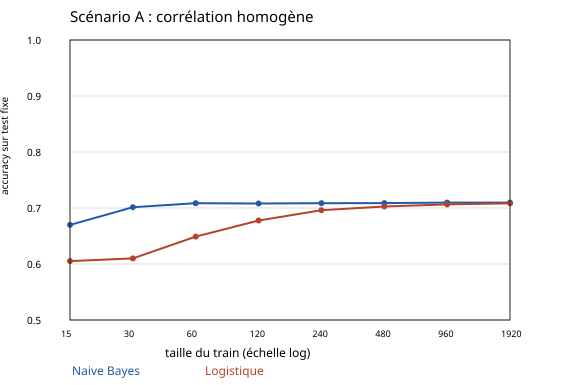

In [7]:
// Scénario A : calculer les 40 tirages et afficher les deux courbes.
var curveA = EvaluateCurve(false,12,.9,.6,1);
PrintCurve(curveA);
display(new CurveSvg(PlotCurve(curveA,"Scénario A : corrélation homogène")), "image/svg+xml");

### Lecture A — l'avantage génératif sur ce petit échantillon

À `n=30`, l'accuracy moyenne de Naive Bayes dépasse celle de la logistique d'environ `0,09`, soit **9 points de pourcentage**. GaussianNB estime séparément une moyenne et une variance pour chaque classe et chaque variable ; il ne partage pas l'information entre variables par un modèle de bloc. La contrainte d'indépendance peut modifier le compromis biais–variance, mais ces moyennes seules ne mesurent pas séparément les deux contributions.

À `n=1920`, l'écart observé tombe à environ `0,001`. Dans ce scénario, la corrélation conditionnelle `ρ=0,6` viole l'indépendance supposée, mais une densité mal spécifiée peut néanmoins induire une frontière de classification adéquate. Cet accord empirique ne garantit pas une calibration correcte des probabilités ni une loi générale.


     n       NB       LR    NB-LR


    15   0.6694   0.7002  -0.0308


    30   0.7188   0.7221  -0.0033


    60   0.7335   0.7557  -0.0222


   120   0.7455   0.7876  -0.0420


   240   0.7451   0.8086  -0.0635


   480   0.7468   0.8159  -0.0690


   960   0.7475   0.8197  -0.0723


  1920   0.7457   0.8216  -0.0760


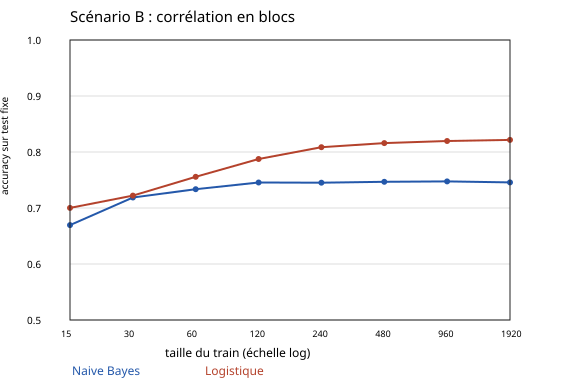

In [8]:
// Scénario B : mêmes budgets, génération en blocs et autre graine.
var curveB = EvaluateCurve(true,12,.7,.85,2);
PrintCurve(curveB);
display(new CurveSvg(PlotCurve(curveB,"Scénario B : corrélation en blocs")), "image/svg+xml");

### Lecture B — comparaison sur le scénario en blocs

Ici la corrélation **en bloc** (la moitié des variables se ressemblent fortement) **viole l'indépendance** que Naive Bayes suppose. Les résultats diffèrent de ceux du scénario A sur cette grille :

- Naive Bayes **stagne autour de ~0.745** dès `n ≈ 120` : il fait son **biais** (une frontière imposée par une hypothèse fausse) et **sur cette grille, augmenter n l'améliore peu** — ce résultat suggère un biais de spécification, sans établir une limite asymptotique à lui seul.
- La logistique **continue de progresser sur cette grille** : elle passe de ~0.70 en petit `n` à **~0.82** à `n = 1920`, **creusant l'écart** (jusqu'à **~-0.076**) qu'elle menait déjà.

Le contraste montre que les deux distributions produisent ici des courbes différentes. Les deux violent l'indépendance conditionnelle ; ce seul constat ne détermine ni le gagnant ni la qualité de ses probabilités. Une frontière de classement peut rester utile même lorsque la densité supposée est imparfaite.

### Exercice 2 — faire varier la dimension

Les courbes ci-dessus utilisent `d = 12`. Dans le scénario A, fais varier `d` (ex. `d = 4`, `d = 24`) et observe comment l'avantage de Naive Bayes en petit `n` **change**. Que se passe-t-il quand la dimension augmente ? Pourquoi ?

In [9]:
Dictionary<int,double> ExerciseDimensions(int[] dimensions, int seed)
{
    // TODO : relancer chaque courbe complète et renvoyer NB−logistique à n=30.
    return null;
}
var dimensionFixtures = new[] { (new[] {4,12,24},1), (new[] {4},3) };
var dimensionAnswers = dimensionFixtures.Select(fixture => ExerciseDimensions(fixture.Item1,fixture.Item2)).ToArray();
if (dimensionAnswers.All(answer => answer == null))
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if (dimensionAnswers.Any(answer => answer == null))
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    bool ok = true;
    for (int i=0; i<dimensionFixtures.Length; i++)
    {
        var (dimensions,seed) = dimensionFixtures[i];
        var answer = dimensionAnswers[i];
        if (answer.Count != dimensions.Length || !dimensions.All(answer.ContainsKey))
        {
            ok = false;
            continue;
        }
        foreach (int dimension in dimensions)
        {
            var curve = EvaluateCurve(false,dimension,.9,.6,seed);
            double expected = curve.Naive[1] - curve.Logistic[1];
            ok = ok && double.IsFinite(answer[dimension]) && Math.Abs(answer[dimension]-expected)<1e-10;
        }
    }
    Console.WriteLine(ok ? "Exercice 2 : calculs corrects ; examiner courbes et interprétation" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


### Ce que vous devriez observer — le guide de l'exercice 2

Comparer les écarts `NB−LR` à `n=30` pour les dimensions demandées et leur dispersion sur les tirages ; ne pas supposer une évolution monotone. Pour deux classes et `d` variables, GaussianNB estime `4d` moyennes et variances ainsi qu'un prior indépendant : chaque groupe de paramètres de classe est estimé à partir de ses `n_c` observations. Une logistique binaire estime `d` coefficients et un intercept, soit `d+1` paramètres.

Le nombre brut de paramètres ne suffit pas à conclure quel estimateur aura le plus faible risque : la structure du modèle, les covariances, le bruit et les données comptent aussi. Les scénarios A et B illustrent des comportements de ce protocole, sans établir un plafond universel quand la dimension augmente.


### 3. Quand choisir lequel — la table de décision mesurée

| Situation | Hypothèse ou contrôle | Mesure ici |
|---|---|---|
| Petit échantillon, corrélation homogène | Comparer les modèles malgré la dépendance entre variables | Scénario A : NB−LR `+0,0916` à n=30 |
| Taille élevée | Examiner le comportement dans chaque scénario | A : écart proche de zéro ; B : LR−NB environ `0,076` à n=1920 |
| Variables fortement corrélées | L'indépendance conditionnelle de NB est violée | Scénario B : NB proche de `0,745` sur les plus grandes tailles de cette grille |
| Besoin de probabilités calibrées | Aucun modèle ne garantit seul la calibration | À vérifier sur des données réservées |

Ces observations suggèrent des candidats à comparer, pas une règle universelle : tester la généralisation, la calibration et les hypothèses sur les données visées. Une corrélation omise peut affecter les probabilités sans nécessairement rendre la frontière de classement mauvaise.


### Exercice 3 — reconnaître le régime

Deux situations types, décrites par leurs propriétés statistiques : (a) **spam vs non-spam** (comptages de mots : très haute dimension, petites corrélations), (b) **série temporelle financière** (variables fortement liées). Pour chacun, dis quel classifieur (génératif ou discriminatif) est le plus adapté **et** quelle hypothèse de Naive Bayes est en jeu. Justifie par le compromis mesuré ci-dessus — l'exercice se joue sur les scénarios A et B déjà mesurés, sans charger de nouveau jeu de données.

In [10]:
(double? A,double? B,string Explanation) ExerciseRegimes(NbCurve a,NbCurve b,int n)
{
    // TODO : retourner les deux écarts NB−LR et une justification argumentée.
    return (null,null,null);
}
var regimeSizes = new[] {30,120};
var regimeAnswers = regimeSizes.Select(n => ExerciseRegimes(curveA,curveB,n)).ToArray();
if (regimeAnswers.All(a => a.A==null && a.B==null && a.Explanation==null))
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if (regimeAnswers.Any(a => a.A==null || a.B==null || a.Explanation==null))
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool ok = true;
    for (int i=0; i<regimeSizes.Length; i++)
    {
        int k = Array.IndexOf(curveA.Sizes,regimeSizes[i]);
        var answer = regimeAnswers[i];
        ok = ok && double.IsFinite(answer.A.Value) && double.IsFinite(answer.B.Value)
            && Math.Abs(answer.A.Value-(curveA.Naive[k]-curveA.Logistic[k]))<1e-10
            && Math.Abs(answer.B.Value-(curveB.Naive[k]-curveB.Logistic[k]))<1e-10
            && answer.Explanation.Trim().Length>=20;
    }
    Console.WriteLine(ok ? "Exercice 3 : écarts cohérents ; discuter les arguments et limites" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


### Choisir et argumenter — guide de l'exercice 3

Les deux scénarios sont des étalons de comparaison : à `n=15`, A donne un écart NB−LR d'environ `+0,065` malgré `ρ=0,6` ; dans B, les écarts à `n=30` et `60` valent environ `−0,003` et `−0,022`. Ils ne démontrent pas à eux seuls le meilleur choix sur des textes ou des séries financières.

Pour chaque situation, discuter les dépendances plausibles entre variables, la taille du train et l'objectif de prédiction, puis proposer une comparaison sur des données réservées. Les mots ne sont pas indépendants par nature ; une corrélation omise ne suffit pas à conclure à une erreur de classement.

Dans le cas spam/non-spam, le modèle multinomial peut servir de point de départ pour des comptages de mots et le lissage traite les mots absents d'une classe ; les dépendances entre mots et le nombre d'exemples étiquetés restent à examiner. Pour des séries financières, les variables peuvent être corrélées et changer dans le temps : une séparation chronologique et une évaluation hors échantillon éclairent mieux le choix qu'une règle fondée sur la seule corrélation. Dans les deux cas, comparer les probabilités et l'accuracy répond à deux questions différentes.


### À retenir

Naive Bayes modélise `P(x|y)` et le prior ; la logistique modélise directement `P(y|x)`. Leurs hypothèses, la taille du train et l'objectif de prédiction influencent la comparaison ; aucune méthode ne gagne dans tous les régimes.

| Concept | Mesure dans ce carnet |
|---|---|
| Vérification from scratch | Accuracy `0,925` et prédictions identiques à sklearn sur ce seul tirage : contrôle utile, pas preuve générale |
| A, corrélation homogène `ρ=0,6` | NB−LR `+0,0647` à n=15 et `+0,0916` à n=30 ; l'indépendance est pourtant violée |
| B, corrélation en blocs `ρ=0,85` | NB−LR `−0,0308` à n=15, `−0,0033` à n=30, `−0,0222` à n=60 et environ `−0,076` à n=1920 |
| Données et modèle | Comparer erreur de classification et calibration : une densité mal spécifiée peut conserver une frontière utile |
| Coût et interprétation | Les 40 tirages et le test fixe décrivent ces expériences ; aucune règle universelle de classement n'en découle |

Dans le scénario A, les moyennes affichées donnent aussi NB−LR environ `+0,0596` à n=60 et un écart proche de `+0,001` à n=1920 : cette diminution décrit la grille observée, sans mesurer séparément le biais et la variance. Dans le scénario B, NB reste proche de `0,745` sur les tailles élevées de la grille tandis que la logistique atteint environ `0,822` à n=1920. Les 40 tirages partagent un jeu de test fixe ; leur moyenne décrit ce protocole et non toutes les populations.

La frontière peut rester adaptée même si les distributions conditionnelles supposées ne le sont pas ; la qualité des probabilités doit être évaluée séparément. Pour classifier, les scores de log-vraisemblance et le prior suffisent à choisir un maximum sans multiplier des probabilités très petites. Pour un usage probabiliste, comparer aussi des scores de calibration sur un jeu indépendant.

**Transition.** Le carnet suivant, [2.3c-Regression-Grande-Dimension](2.3c-Regression-Grande-Dimension.ipynb), étudie la régression lorsque le nombre de variables dépasse celui des exemples.


### Vérifiez votre compréhension

**1. La cellule de vérification affiche `accuracy from scratch : 0.925`, `accuracy sklearn : 0.925`, `predictions identiques : True`. Que prouvent ces trois nombres ensemble ?**

<details>
<summary>Réponse</summary>

Ces sorties montrent une même accuracy et les mêmes prédictions sur ce tirage ; les moyennes affichées apportent un contrôle complémentaire. Elles ne prouvent ni l'égalité exacte de toutes les variances et probabilités, ni la correction sur toutes les données. D'autres jeux et la comparaison des log-vraisemblances permettent de renforcer le contrôle.
</details>

**2. Dans le scénario A, l'avantage de NB passe de `+0.0916` (n=30) à `+0.0596` (n=60). Que montre cet écart sur ce tirage et que ne prouve-t-il pas ?**

<details>
<summary>Réponse</summary>

Une explication possible sur ce tirage est un compromis entre les contraintes du modèle génératif et la variance de l’estimation ; elle demande d’être vérifiée sur d’autres jeux. Dans la grille affichée l'écart diminue ; cela ne prouve pas une règle générale ni une décomposition mesurée du risque entre biais et variance.
</details>

**3. Dans le scénario B (blocs corrélés à ρ = 0.85), LR dépasse NB dès n=15 (`0.7002` contre `0.6694`). Que suggère cet écart et quelles vérifications restent nécessaires ?**

<details>
<summary>Réponse</summary>

Les corrélations en blocs violent l'indépendance conditionnelle, ce qui peut fausser les densités et les probabilités. Sur cette grille, NB progresse peu aux grandes tailles tandis que la logistique obtient une meilleure accuracy. Ces observations suggèrent un effet de spécification, sans prouver un plafond asymptotique ni exclure une frontière utile sous une autre distribution. Comparer aussi calibration et alternatives comme LDA/QDA.
</details>

Les réponses ci-dessus sont des interprétations du tirage : l’accord de prédictions ne démontre pas l’égalité de toutes les densités ou probabilités, et plus de données ne garantit pas un classement particulier des modèles.


### Pour aller plus loin

- [README de la sous-série 02-ML-Cours](README.md) — la carte des carnets et de leurs concepts-phares.
- [README de la série DataScienceWithAgents](../README.md) — le rôle de ce socle ML dans la formation.
- [2.3c-Regression-Grande-Dimension](2.3c-Regression-Grande-Dimension.ipynb) — la suite immédiate : régresser quand `p` dépasse `n`.
- [2.3d-Modele-Gaussien-LDA-QDA](2.3d-Modele-Gaussien-LDA-QDA.ipynb) — l'autre famille générative : gaussienne cette fois, avec covariances complètes au lieu de l'indépendance.
- [2.3-Regression-lineaire-logistique](2.3-Regression-lineaire-logistique.ipynb) — la référence de la régression logistique confrontée ici.

## Références

* Deisenroth, M.P., Faisal, A.A. & Ong, C.S. (2020). *Mathematics for
Machine Learning*. Cambridge UP. — ch. 6 (Probability and
Distributions) pose le formalisme des distributions gaussiennes
et multinomiales, l'estimation par maximum de vraisemblance, et
la classification bayésienne naïve que ce carnet implémente.
C'est la référence mathématique qui sous-tend `GaussianNB` et
`MultinomialNB` de scikit-learn.

